# DenseNet-161 (state-of-the-art reference)

Reproduces the DenseNet result reported on PlantVillage by Jeevan & Sethi (2024),
*A Resource-Efficient Domain-Specific Comparison for Computer Vision*
([arXiv:2406.05612](https://arxiv.org/abs/2406.05612)), on our 21-class, CycleGAN-balanced dataset.

**Setup:** ImageNet-pretrained DenseNet-161, AdamW with mixed precision, 31 epochs.

**Result:** 99.16% top-1 accuracy (best epoch).

> ⚠️ The reported accuracy is the best epoch measured on the test set itself, and this
> notebook uses its own random split, so it is not directly comparable with the
> EfficientNet-B7 test set. See the README.


In [ ]:
!pip install dualopt



In [ ]:
!pip install torchinfo


In [ ]:
!pip install lion_pytorch

In [ ]:
!pip install wavemix

In [ ]:
!gdown --id 1r4LvjGBfe0Fhl4Vqsn8fOrtkH-IaqXaa

In [ ]:
!unzip /content/data.zip -d /content/plantvillage_dataset

In [ ]:
import pandas as pd

In [ ]:
import dualopt, torch, wavemix, torchvision
from wavemix.classification import WaveMix
import torchvision.transforms as transforms
import torch, math
import torchvision
import torch.nn as nn
from torchmetrics.classification import Accuracy
from lion_pytorch import Lion
import wavemix
from wavemix import DWTForward, Level3Waveblock, Level2Waveblock, Level1Waveblock
from wavemix.classification import WaveMix
import numpy as np
from torchinfo import summary
import time
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import ConcatDataset
import argparse
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from tqdm import tqdm
from torchmetrics.classification import Accuracy
import os

In [ ]:
# Set device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Define model and batch size directly
model_name = "densenet"  # Change this to "densenet" as per your request
batch_size = 32  # Set your desired batch size

num_classes = 21

# Model initialization for DenseNet
if model_name == "densenet":
    from torchvision.models import densenet161, DenseNet161_Weights
    model = densenet161(weights=DenseNet161_Weights.IMAGENET1K_V1)
    model.classifier = nn.Linear(2208, num_classes)  # Adjust classifier for your number of classes

model.to(device)
print(summary(model, (1, 3, 256, 256)))

# Define transformations
transform_test = transforms.Compose(
    [
        transforms.Resize([256, 256]),
        transforms.ToTensor(),
        transforms.Normalize((0.4669, 0.4890, 0.4129), (0.2002, 0.1768, 0.2193))
    ]
)

transform_train = transforms.Compose(
    [
        transforms.Resize([256, 256]),
        transforms.ToTensor(),
        transforms.Normalize((0.4666, 0.4891, 0.4118), (0.2006, 0.1771, 0.2194))
    ]
)

# Load dataset
data_dir = '/content/plantvillage_dataset/content/PlantData/PlantVillage-Dataset/raw/color'
trainset1 = torchvision.datasets.ImageFolder(root=data_dir, transform=transform_train)

# Split dataset
train_size = int(0.7 * len(trainset1))
val_size = len(trainset1) - train_size
trainset, testset = random_split(trainset1, [train_size, val_size])

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=2)

testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size * 2,
                                         shuffle=False, num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=2)

# Metrics and loss
top1_acc = Accuracy(task="multiclass", num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
scaler = torch.cuda.amp.GradScaler()

top1 = [0]
traintime = []
testtime = []
counter = 0

# Optimizer
optimizer = optim.AdamW(model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0.01, amsgrad=False)
print("Training with AdamW")

# Training loop
PATH = 'train.pth'
epoch = 0
while counter < 10:  # Counter sets the number of epochs of non-improvement before stopping
    t0 = time.time()
    epoch_accuracy = 0
    epoch_loss = 0
    model.train()

    with tqdm(trainloader, unit="batch") as tepoch:
        tepoch.set_description(f"Epoch {epoch + 1}")

        for data in tepoch:
            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            acc = (outputs.argmax(dim=1) == labels).float().mean()
            epoch_accuracy += acc / len(trainloader)
            epoch_loss += loss / len(trainloader)
            tepoch.set_postfix_str(f" loss : {epoch_loss:.4f} - acc: {epoch_accuracy:.4f}")

    correct_1 = 0
    c = 0
    model.eval()
    t1 = time.time()
    with torch.no_grad():
        for data in testloader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = model(images)
            correct_1 += top1_acc(outputs, labels)
            c += 1

    print(f"Epoch : {epoch + 1} - Top 1: {correct_1 * 100 / c:.2f} - Train Time: {t1 - t0:.2f} - Test Time: {time.time() - t1:.2f}\n")

    if float(correct_1 * 100 / c) > float(max(top1)):
        torch.save(model.state_dict(), PATH)
        print(1)
        counter = 0
    top1.append(correct_1 * 100 / c)
    traintime.append(t1 - t0)
    testtime.append(time.time() - t1)
    counter += 1
    epoch += 1

print('Finished Training')
print("Results")
print(f"Top 1 Accuracy: {max(top1):.2f}  - Train Time: {min(traintime):.0f} - Test Time: {min(testtime):.0f}\n")

<ipython-input-12-ea00fc83dcc2>:54: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Layer (type:depth-idx)                   Output Shape              Param #
DenseNet                                 [1, 21]                   --
├─Sequential: 1-1                        [1, 2208, 8, 8]           --
│    └─Conv2d: 2-1                       [1, 96, 128, 128]         14,112
│    └─BatchNorm2d: 2-2                  [1, 96, 128, 128]         192
│    └─ReLU: 2-3                         [1, 96, 128, 128]         --
│    └─MaxPool2d: 2-4                    [1, 96, 64, 64]           --
│    └─_DenseBlock: 2-5                  [1, 384, 64, 64]          --
│    │    └─_DenseLayer: 3-1             [1, 48, 64, 64]           101,952
│    │    └─_DenseLayer: 3-2             [1, 48, 64, 64]           111,264
│    │    └─_DenseLayer: 3-3             [1, 48, 64, 64]           120,576
│    │    └─_DenseLayer: 3-4             [1, 48, 64, 64]           129,888
│    │    └─_DenseLayer: 3-5             [1, 48, 64, 64]           139,200
│    │    └─_DenseLayer: 3-6             [1, 48, 64, 64

Epoch 1:   0%|          | 0/808 [00:00<?, ?batch/s]<ipython-input-12-ea00fc83dcc2>:80: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1: 100%|██████████| 808/808 [01:48<00:00,  7.46batch/s,  loss : 0.2413 - acc: 0.9248]


Epoch : 1 - Top 1: 96.91 - Train Time: 108.31 - Test Time: 22.50

1


Epoch 2: 100%|██████████| 808/808 [01:48<00:00,  7.47batch/s,  loss : 0.1040 - acc: 0.9655]


Epoch : 2 - Top 1: 94.42 - Train Time: 108.15 - Test Time: 22.07



... (54 outputs left out)

Epoch 30: 100%|██████████| 808/808 [01:46<00:00,  7.59batch/s,  loss : 0.0166 - acc: 0.9948]


Epoch : 30 - Top 1: 98.73 - Train Time: 106.45 - Test Time: 22.19



Epoch 31: 100%|██████████| 808/808 [01:47<00:00,  7.54batch/s,  loss : 0.0147 - acc: 0.9959]


Epoch : 31 - Top 1: 98.65 - Train Time: 107.23 - Test Time: 22.08

Finished Training
Results
Top 1 Accuracy: 99.16  - Train Time: 106 - Test Time: 22



In [ ]:
import matplotlib.pyplot as plt
import random
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
all_preds = []
all_labels = []
all_probs = []

model.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = model(images)

        preds = outputs.argmax(dim=1)
        probs = torch.softmax(outputs, dim=1)  # Get probabilities

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())  # Extend instead of append


In [ ]:
all_probs = np.array(all_probs)  # Convert to numpy array


In [ ]:



# Generate the classification report
print(classification_report(all_labels, all_preds, target_names=trainset1.classes))

                                               precision    recall  f1-score   support

                           Apple___Apple_scab       1.00      0.99      1.00       488
                            Apple___Black_rot       1.00      1.00      1.00       521
                     Apple___Cedar_apple_rust       1.00      1.00      1.00       507
                              Apple___healthy       0.98      1.00      0.99       446
                          Blueberry___healthy       1.00      0.99      1.00       453
                            Grape___Black_rot       0.99      0.80      0.89       475
                              Grape___healthy       0.80      1.00      0.89       389
     Orange___Haunglongbing_(Citrus_greening)       1.00      1.00      1.00       589
                       Peach___Bacterial_spot       1.00      1.00      1.00       618
                              Peach___healthy       1.00      1.00      1.00       524
                Pepper,_bell___Bacterial_s

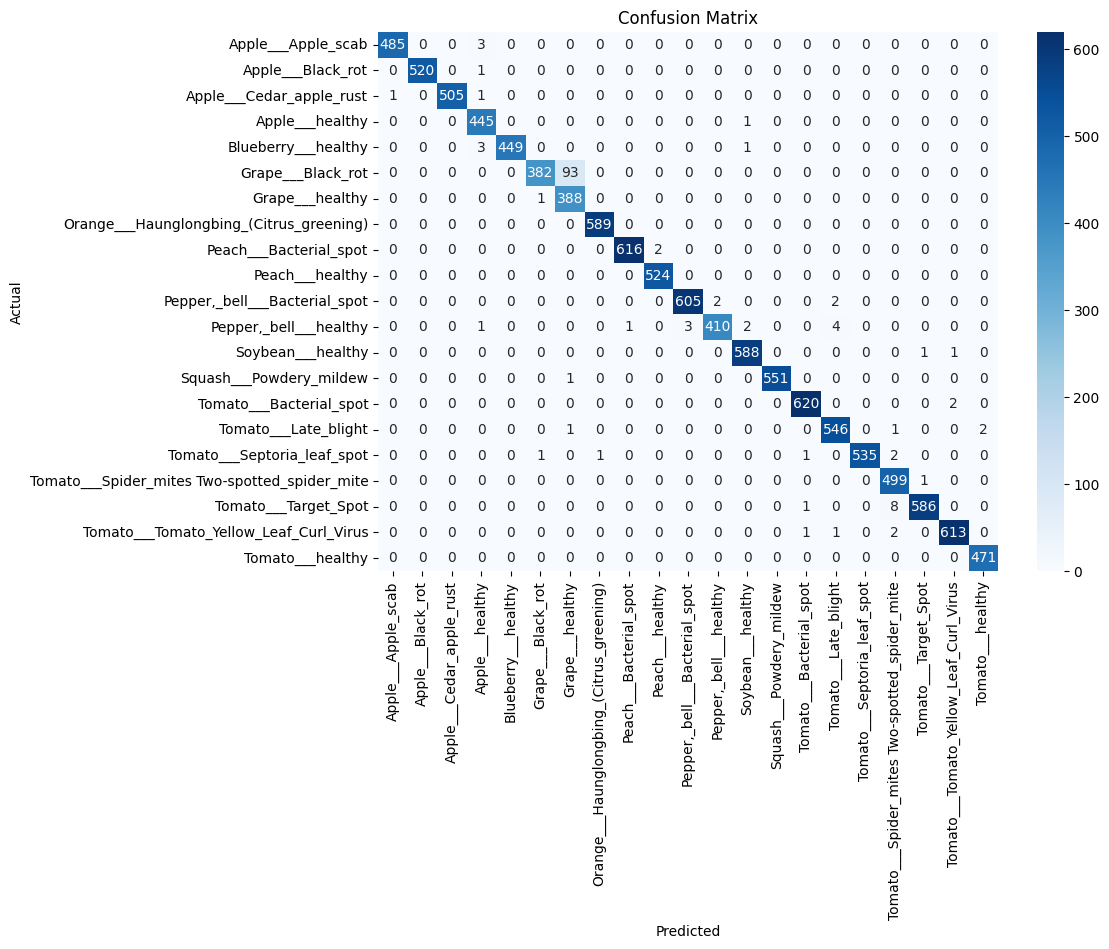

In [ ]:
conf_matrix = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=trainset1.classes, yticklabels=trainset1.classes)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()


AUC Score: 1.00


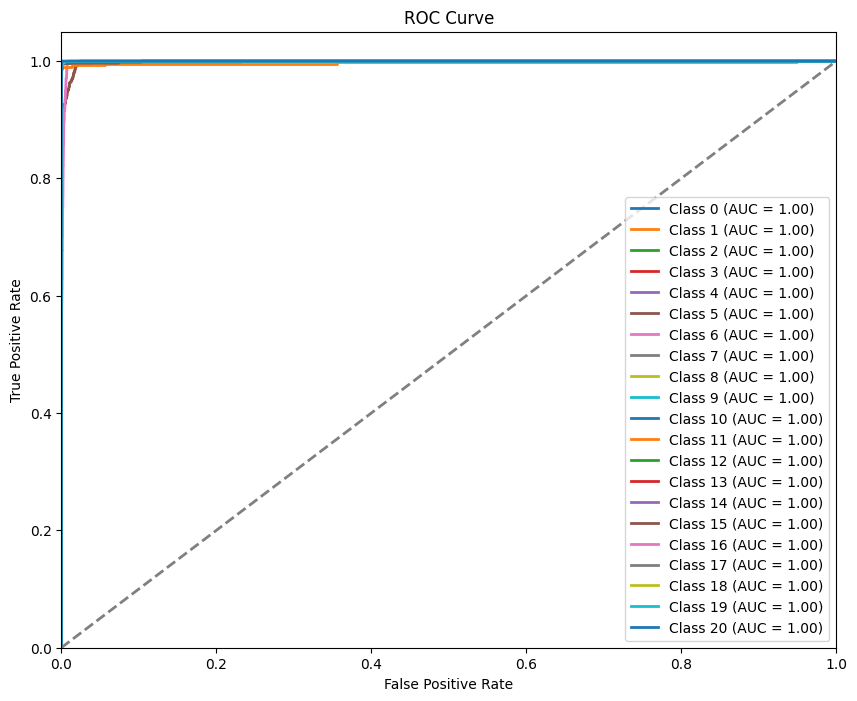

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

all_preds = []
all_labels = []
all_probs = []

model.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = model(images)

        preds = outputs.argmax(dim=1)
        probs = torch.softmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

auc_score = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='macro')
print(f"AUC Score: {auc_score:.2f}")

n_classes = len(np.unique(all_labels))
plt.figure(figsize=(10, 8))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(all_labels, all_probs[:, i], pos_label=i)
    plt.plot(fpr, tpr, lw=2, label=f'Class {i} (AUC = {roc_auc_score(all_labels == i, all_probs[:, i]):.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

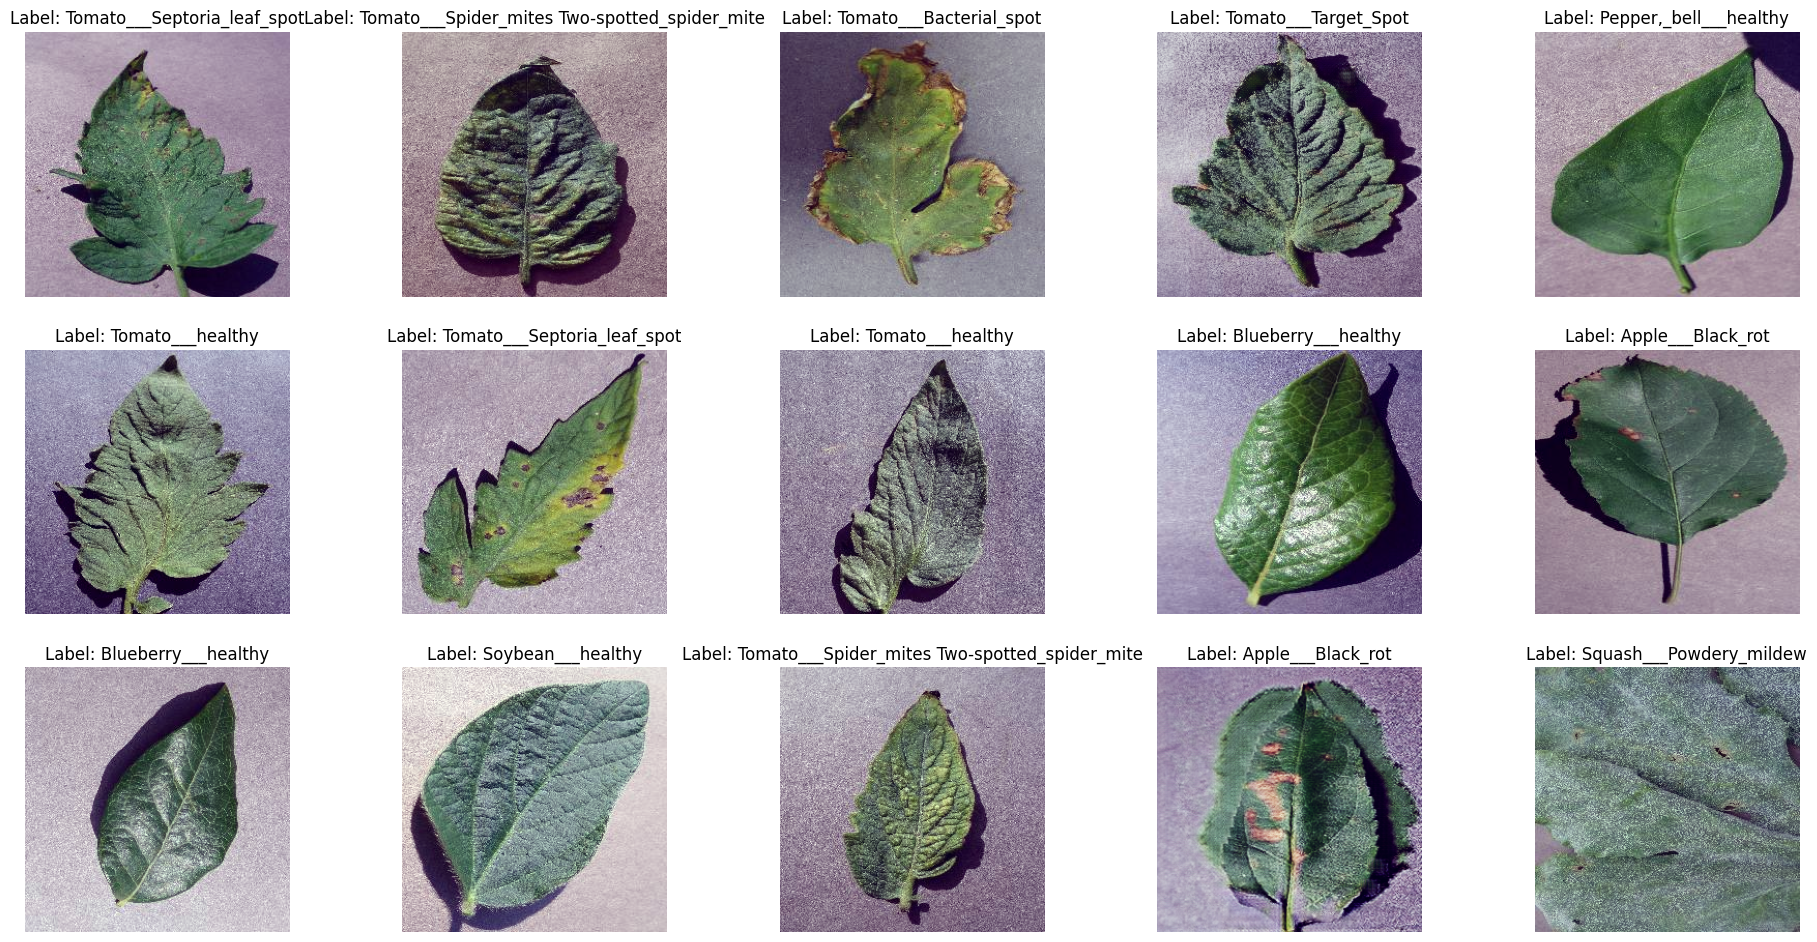

In [ ]:
# Show samples in a grid layout, with a new line after every 5 samples
def show_samples(dataset, num_samples=10):
    num_cols = 5  # Number of columns
    num_rows = (num_samples + num_cols - 1) // num_cols  # Calculate number of rows needed

    plt.figure(figsize=(20, num_rows * 4))  # Adjust figure size based on number of rows
    indices = random.sample(range(len(dataset)), num_samples)  # Randomly select indices

    for i, idx in enumerate(indices):
        img, label = dataset[idx]
        img = img.permute(1, 2, 0)  # Change to HWC format for displaying
        img = img * 0.2006 + 0.4666  # Unnormalize (inverse of normalization)
        img = img.clip(0, 1)  # Clip values to be in valid range

        plt.subplot(num_rows, num_cols, i + 1)  # Create a grid layout
        plt.imshow(img)
        plt.title(f'Label: {dataset.classes[label]}', fontsize=12)  # Increase title font size
        plt.axis('off')

        # Adjust spacing between images and titles
        plt.subplots_adjust(left=0.05, right=0.95, top=0.85, bottom=0.1, wspace=0.3)

    plt.show()

# Show samples
show_samples(trainset1, num_samples=15)